# Сокращение размерности

В каждом из заданий:
* Обучите два классификатора (svm и логистическую регрессию на датасете данном ниже) в датасете размерность из 30 признаков
* Попребирайте различное количество итоговых размерностей и постройте графики качества от количества размерностей. Выведите обе модели на одном графике в каждой заадче

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import decomposition
from sklearn import datasets
from sklearn import svm
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import cross_val_score, StratifiedKFold

np.random.seed(5)
dataset = datasets.load_breast_cancer()
X = dataset.data
y = dataset.target

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
def build_classicators():
    return (
        make_pipeline(StandardScaler(), svm.SVC(kernel='linear')),
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    )


def get_score(X, y):
    m_svm, m_lr = build_classicators()
    s_svm = cross_val_score(m_svm, X, y, cv=cv, n_jobs=-1).mean() #средние точности
    s_lr = cross_val_score(m_lr,  X, y, cv=cv, n_jobs=-1).mean()
    return s_svm, s_lr


def plot_curve(dims, svm_scores, lr_scores, title, xlabel):
    plt.figure(figsize=(9, 5))
    plt.plot(dims, svm_scores, 'o-', label='SVM (linear)')
    plt.plot(dims, lr_scores,  's-', label='LogisticRegression')
    plt.xlabel(xlabel)
    plt.ylabel('CV accuracy')
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [4]:
results_store = {}

# Lasso regularization (2pts)

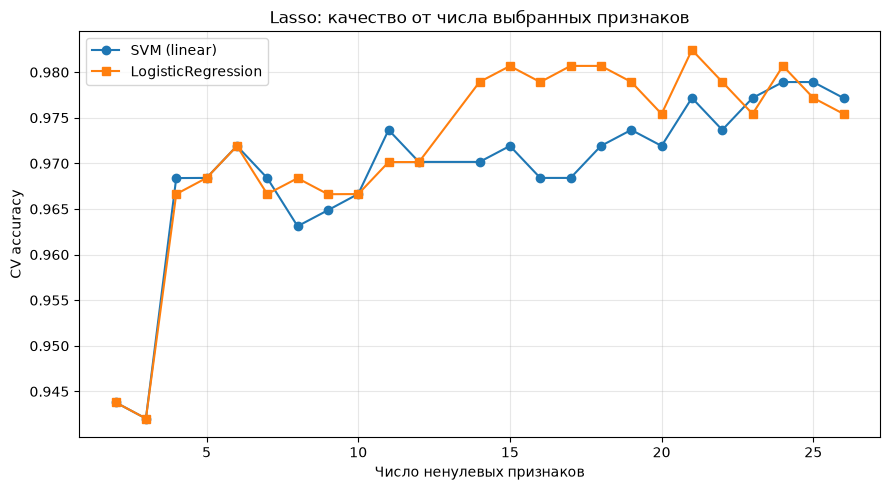

In [5]:
X_scaled = StandardScaler().fit_transform(X)

alphas = np.logspace(-4, 0.5, 80)
best_by_n = {}
for a in alphas:
    lasso = Lasso(alpha=a, max_iter=20000)
    lasso.fit(X_scaled, y)
    mask = np.abs(lasso.coef_) > 1e-6
    n = int(mask.sum())
    if n == 0 or n == X.shape[1]:
        continue
    s_svm, s_lr = get_score(X[:, mask], y)# Оцениваем SVM и LR только на отобранных по маске столбцах
    if n not in best_by_n or (s_svm + s_lr) > sum(best_by_n[n]): # Если для такого числа признаков n ещё нет записи или сумма точностей выше прежней
        best_by_n[n] = (s_svm, s_lr)

dims = sorted(best_by_n)
svm_s = [best_by_n[d][0] for d in dims]# списки точностей SVM/lr
lr_s = [best_by_n[d][1] for d in dims]
results_store['lasso'] = (dims, svm_s, lr_s)

plot_curve(dims, svm_s, lr_s,
           'Lasso: качество от числа выбранных признаков',
           'Число ненулевых признаков')

# Forward selection (2pts)

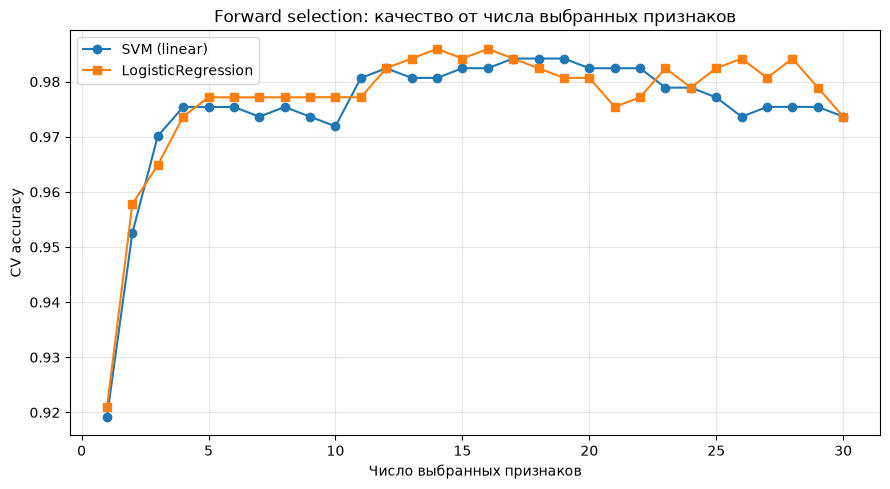

In [7]:
selected = []
remaining = list(range(X.shape[1]))

fwd_dims, fwd_svm, fwd_lr = [], [], []

for step in range(1, X.shape[1] + 1):
    best = None

    for j in remaining:
        cand = selected + [j]
        s_svm, s_lr = get_score(X[:, cand], y)
        combined = s_svm + s_lr# критерий-сумма точностей обеих моделей

        if best is None or combined > best[0]:
            best = (combined, j, s_svm, s_lr)

    _, best_j, s_svm, s_lr = best
    selected.append(best_j)
    remaining.remove(best_j)

    fwd_dims.append(len(selected))
    fwd_svm.append(s_svm)
    fwd_lr.append(s_lr)

results_store['forward'] = (fwd_dims, fwd_svm, fwd_lr)

plot_curve(
    fwd_dims, fwd_svm, fwd_lr,
    'Forward selection: качество от числа выбранных признаков',
    'Число выбранных признаков'
)

# Backward elimination (2pts)

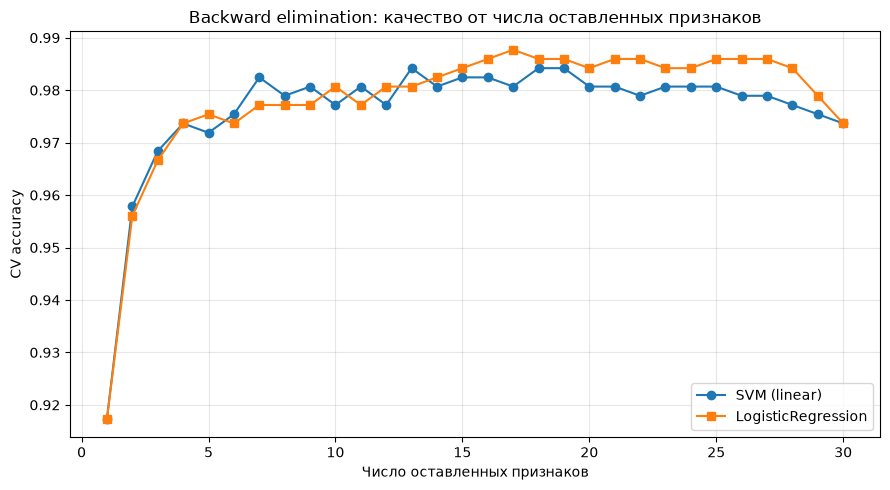

In [9]:
selected = list(range(X.shape[1]))

bwd_dims, bwd_svm, bwd_lr = [], [], []

s_svm, s_lr = get_score(X[:, selected], y)
bwd_dims.append(len(selected))
bwd_svm.append(s_svm)
bwd_lr.append(s_lr)

while len(selected) > 1:
    best = None

    for j in selected:
        cand = [f for f in selected if f != j]
        s_svm, s_lr = get_score(X[:, cand], y)
        combined = s_svm + s_lr

        if best is None or combined > best[0]:
            best = (combined, j, s_svm, s_lr, cand)

    _, removed_j, s_svm, s_lr, selected = best

    bwd_dims.append(len(selected))
    bwd_svm.append(s_svm)
    bwd_lr.append(s_lr)

order = np.argsort(bwd_dims)
bwd_dims = [bwd_dims[i] for i in order]
bwd_svm = [bwd_svm[i] for i in order]
bwd_lr = [bwd_lr[i] for i in order]

results_store['backward'] = (bwd_dims, bwd_svm, bwd_lr)

plot_curve(
    bwd_dims, bwd_svm, bwd_lr,
    'Backward elimination: качество от числа оставленных признаков',
    'Число оставленных признаков'
)

# PCA (2 pts)


### EM алгоритм

Оставлю это тут просто чтобы пугать людей


$$
\log p(x|\theta) = \int q(z)\log p(x|\theta)dz = \int q(z)\log\dfrac{p(x,z|\theta)}{p(z|x,\theta)}dz = \int q(z)\log\dfrac{p(x,z|\theta)}{q(z)}dz+\int q(z)\log\dfrac{q(z)}{p(z|x,\theta)}dz = \mathcal{L}(q,\theta)+KL(q(z)|p(z|x,\theta))
$$

** E-step **
$$ q(z)^{(n+1)} = p(z|x,\theta^{(n)}) $$
** M-step **
$$ \theta^{(n+1)} = \max\limits_{\theta} \mathcal{L}(q^{(n+1)},\theta) $$

Обучите два классификатора (svm и огистическую регрессию на датасете данном ниже) в датасете размерность из 30 признаков. Попребирайте различное количество итоговых размерностей (до которых будет сокращать PCA) и постройте графики для обоих классификаторов. Сделайте выводы.

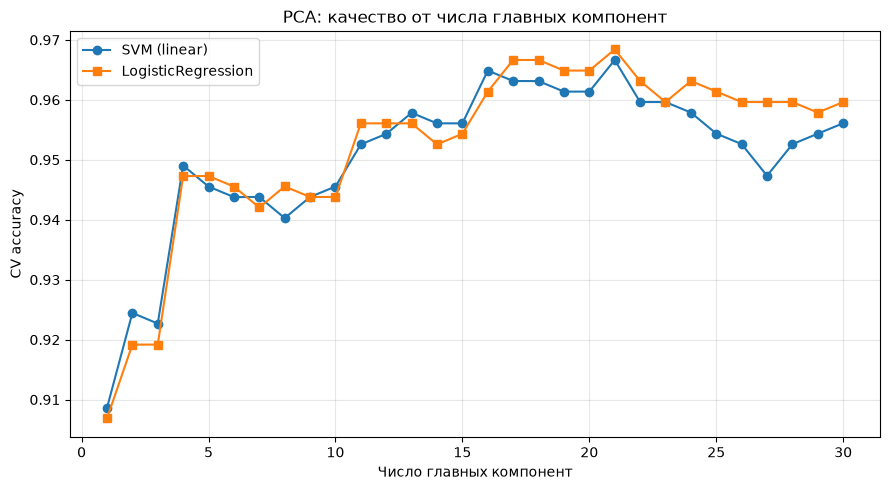

In [13]:
pca_dims = list(range(1, X.shape[1] + 1))
pca_svm, pca_lr = [], []

for n_components in pca_dims:
    pca = decomposition.PCA(n_components=n_components, random_state=42)
    pca.fit(X)
    X2 = pca.transform(X)

    s_svm, s_lr = get_score(X2, y)
    pca_svm.append(s_svm)
    pca_lr.append(s_lr)

results_store['pca'] = (pca_dims, pca_svm, pca_lr)

plot_curve(
    pca_dims, pca_svm, pca_lr,
    'PCA: качество от числа главных компонент',
    'Число главных компонент'
)

#  Выводы (2pts)

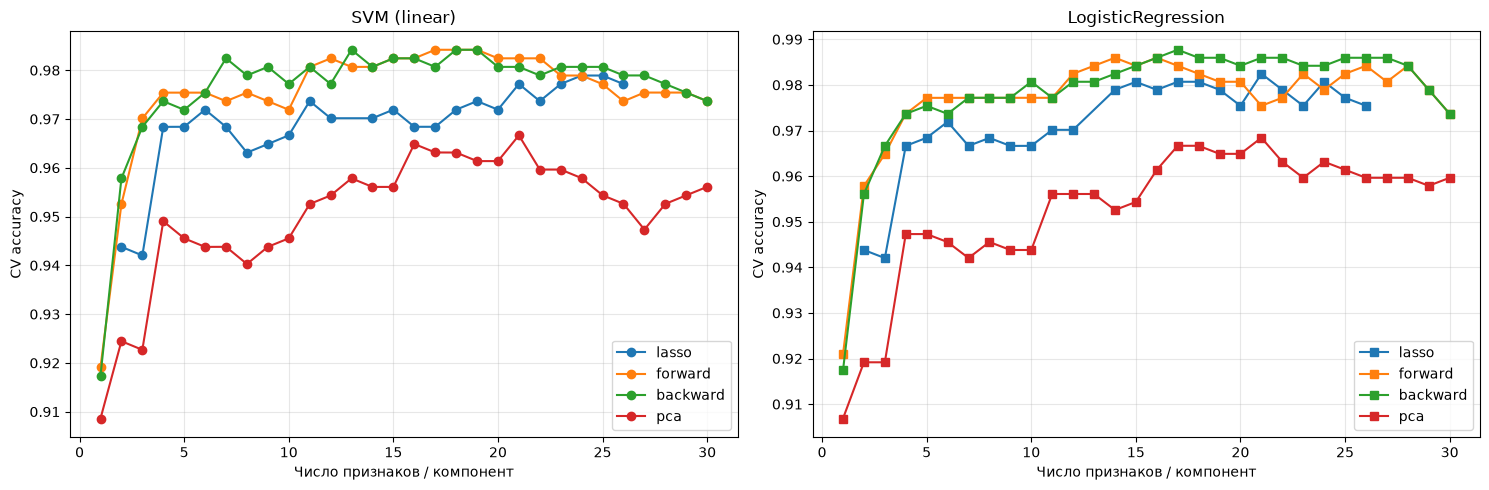

lasso      | SVM: best=0.9789 at dim=24, LR: best=0.9824 at dim=21
forward    | SVM: best=0.9842 at dim=17, LR: best=0.9859 at dim=14
backward   | SVM: best=0.9842 at dim=13, LR: best=0.9877 at dim=17
pca        | SVM: best=0.9667 at dim=21, LR: best=0.9684 at dim=21


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name, (dims, svm_scores, lr_scores) in results_store.items():
    axes[0].plot(dims, svm_scores, marker='o', label=name)
    axes[1].plot(dims, lr_scores, marker='s', label=name)

axes[0].set_title('SVM (linear)')
axes[0].set_xlabel('Число признаков / компонент')
axes[0].set_ylabel('CV accuracy')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].set_title('LogisticRegression')
axes[1].set_xlabel('Число признаков / компонент')
axes[1].set_ylabel('CV accuracy')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

for name, (dims, svm_scores, lr_scores) in results_store.items():
    best_svm_idx = int(np.argmax(svm_scores))
    best_lr_idx = int(np.argmax(lr_scores))
    print(
        f"{name:10s} | "
        f"SVM: best={svm_scores[best_svm_idx]:.4f} at dim={dims[best_svm_idx]}, "
        f"LR: best={lr_scores[best_lr_idx]:.4f} at dim={dims[best_lr_idx]}"
    )